---
title: "Grammar of graphics for SQL? Trying GGSQL"
description: "Querying, analyzing and plotting Japanese infectious surveillance data with nothing but SQL"
date: "2026-10-12"
categories: [Data Visualization, SQL, ggsql, DuckDB, Epidemiology, Japan]
author: Alejandro Fontal
image: featured.png
format:
  html:
    warning: false
    smooth-scroll: true
    toc: true
    syntax-definitions:
      - ggsql.xml
---

In this post I will showcase two tools at once: [`ggsql`](https://ggsql.org), Posit's implementation of the grammar of graphics on top of SQL, and [`jp-idwr-db`](https://github.com/AlFontal/jp-idwr-db), a package I have been building to make Japan's infectious disease surveillance data (IDWR) easier to work with.

I have been using IDWR data for a while in my research on Kawasaki disease, comparing it with other childhood infections, and every time I needed it I ended up scraping the weekly reports one by one, as I could not find an API for them. `jp-idwr-db` is what came out of finally doing that properly, once, so that neither I nor anyone else has to do it again.

The two tools fit together surprisingly well. `jp-idwr-db` publishes its data as plain Parquet files, and `ggsql` lets you go from a SQL query to a plot without ever leaving SQL. So everything that runs below, from downloading the data to the last figure (maps included), is written in SQL. No pandas, no matplotlib, not even a Python kernel.

I have to admit that, coming from Python and R, I don't fully understand why one would *need* to do all of this in pure SQL. It was a fun exercise nevertheless, and by the end of it I did find a few situations where it makes a lot of sense, which I discuss [at the end of the post](#why-would-you-do-this-in-sql).

#### Preamble {-}

<details>
<summary>Show setup instructions</summary>

<br>
`ggsql` ships a Jupyter kernel that runs every cell against an in-memory DuckDB session. To install it in a fresh environment:

```bash
uv venv
uv pip install jupyter ggsql-jupyter
source .venv/bin/activate
ggsql-jupyter --install
```

After that, a `ggsql` kernel shows up in Jupyter, and Quarto documents can use `{ggsql}` code blocks. All cells share the same DuckDB session, which is what makes the rest of this post work: we create tables in one cell and plot them in the next.

The plot size and resolution are not part of a `ggsql` query: the kernel takes them from the frontend, or from the same environment variables Quarto sets for its `fig-width`, `fig-height` and `fig-dpi` options. As my blog renders notebooks without executing them, I ran this one with those variables set by hand, for sharper figures than the 96 dpi default:

```bash
QUARTO_FIG_FORMAT=png QUARTO_FIG_WIDTH=9 QUARTO_FIG_HEIGHT=6 QUARTO_FIG_DPI=200 \
  jupyter nbconvert --to notebook --execute --inplace ggsql_jp_idwr_db.ipynb
```

The kernel reads those variables once, when it starts, so every figure in a session comes out with the same size. For the RSV heatmap, which works better as a wide and short figure, I re-ran its cell in a fresh kernel with a different height.

This post was run with `ggsql-jupyter` 0.5.2.

</details>

## The data

The Japanese National Institute of Infectious Diseases (NIID), which merged into the new Japan Institute for Health Security (JIHS) in April 2025, publishes weekly reports on dozens of notifiable diseases for each of the 47 prefectures: the Infectious Diseases Weekly Report, or IDWR. The data goes back to 1999, but it is spread over different formats and archives: final annual tables in `.xls`/`.xlsx`, preliminary weekly reports in `.csv`, and a few changes in the structure of the files along the way.

`jp-idwr-db` collects all of those files, cleans and combines them, and publishes analysis-ready weekly snapshots as GitHub releases. A scheduled GitHub Action checks for new reports every week. It is inspired by [`jpinfect`](https://github.com/TomonoriHoshi/jpinfect), the R package by Tomonori Hoshi, adapted for Python and for more general usage.

If you are working in Python, getting the data is a one-liner:

```python
import jp_idwr_db as jp

rsv = jp.get_data(
    disease="Respiratory syncytial virus infection",
    year=2024,
    prefecture=["Tokyo", "Osaka"],
    version="v2026.10.7",
)
```

But each release also includes the underlying Parquet files (and even a ready-made DuckDB database), so any tool that reads Parquet can use them directly. That is exactly what we will do here. I am pinning the release (`v2026.10.7`) so the numbers in this post do not change as new weeks are published.

## Loading the data

DuckDB can read Parquet straight from a URL, so loading the whole `unified` dataset (the combined and deduplicated one, recommended for most analyses) is a single statement:

In [1]:
CREATE TABLE idwr AS
SELECT * FROM read_parquet('https://github.com/AlFontal/jp-idwr-db/releases/download/v2026.10.7/unified.parquet')

That is about 6.2 million rows, one per prefecture, ISO week and disease, from April 1999 to September 2026. The rows come from three different surveillance streams:

In [2]:
SELECT
  source,
  MIN(year) AS first_year,
  MAX(year) AS last_year,
  COUNT(DISTINCT disease) AS diseases,
  COUNT(*) AS rows
FROM idwr
GROUP BY source
ORDER BY rows DESC

source,first_year,last_year,diseases,rows
Confirmed cases,1999,2024,94,4537051
Sentinel surveillance,1999,2026,27,1290855
All-case reporting,2025,2026,88,373274


IDWR publishes every year twice: preliminary weekly reports during the year, and final annual tables about 15 months later that include the cases reported late. The `unified` dataset uses the final tables wherever they exist and the preliminary reports only after that, which is why *Confirmed cases* stops in 2024 and *All-case reporting* picks up in 2025. For the sentinel diseases, 2025 and 2026 also come from preliminary reports, so the most recent figures in this post should be read with that in mind. A handful of preliminary sentinel weeks cannot be derived from the published totals; those are left empty (with the reason in `count_status`) rather than imputed.

In this post I will focus on the **sentinel surveillance** stream, which covers the common infections that are reported by a network of sentinel clinics instead of case by case, many of them childhood infections.

## A first plot

Real surveillance data comes with real quirks. Influenza, for example, has been reported under three different names:

In [3]:
SELECT disease, MIN(year) AS first_year, MAX(year) AS last_year
FROM idwr
WHERE source = 'Sentinel surveillance' AND disease LIKE 'Influenza%'
GROUP BY disease
ORDER BY first_year

disease,first_year,last_year
Influenza,1999,2005
Influenza(excld. avian influenza virus infection),2006,2007
Influenza(excld. avian influenza and pandemic influenza),2008,2026


So we will harmonise those names while building a national weekly table for six common infections, summing the counts across prefectures:

In [4]:
CREATE TABLE sentinel AS
SELECT
  year,
  week,
  date,
  CASE
    WHEN disease LIKE 'Influenza%' THEN 'Influenza'
    WHEN disease = 'Respiratory syncytial virus infection' THEN 'RSV'
    WHEN disease = 'Hand, foot and mouth disease' THEN 'HFMD'
    WHEN disease = 'Group A streptococcal pharyngitis' THEN 'Strep A pharyngitis'
    ELSE disease
  END AS disease,
  SUM(count) AS cases
FROM idwr
WHERE source = 'Sentinel surveillance'
  AND (
    disease LIKE 'Influenza%'
    OR disease IN (
      'Respiratory syncytial virus infection',
      'Hand, foot and mouth disease',
      'Herpangina',
      'Group A streptococcal pharyngitis',
      'Mycoplasma pneumonia'
    )
  )
GROUP BY ALL

Now the `ggsql` part. A `ggsql` query is a regular SQL query followed by a description of the plot. Everything before `VISUALISE` is sent to DuckDB as usual; `VISUALISE` maps columns to aesthetics, `DRAW` adds layers, and `FACET`, `SCALE` and `LABEL` do what anyone coming from `ggplot2` would expect:

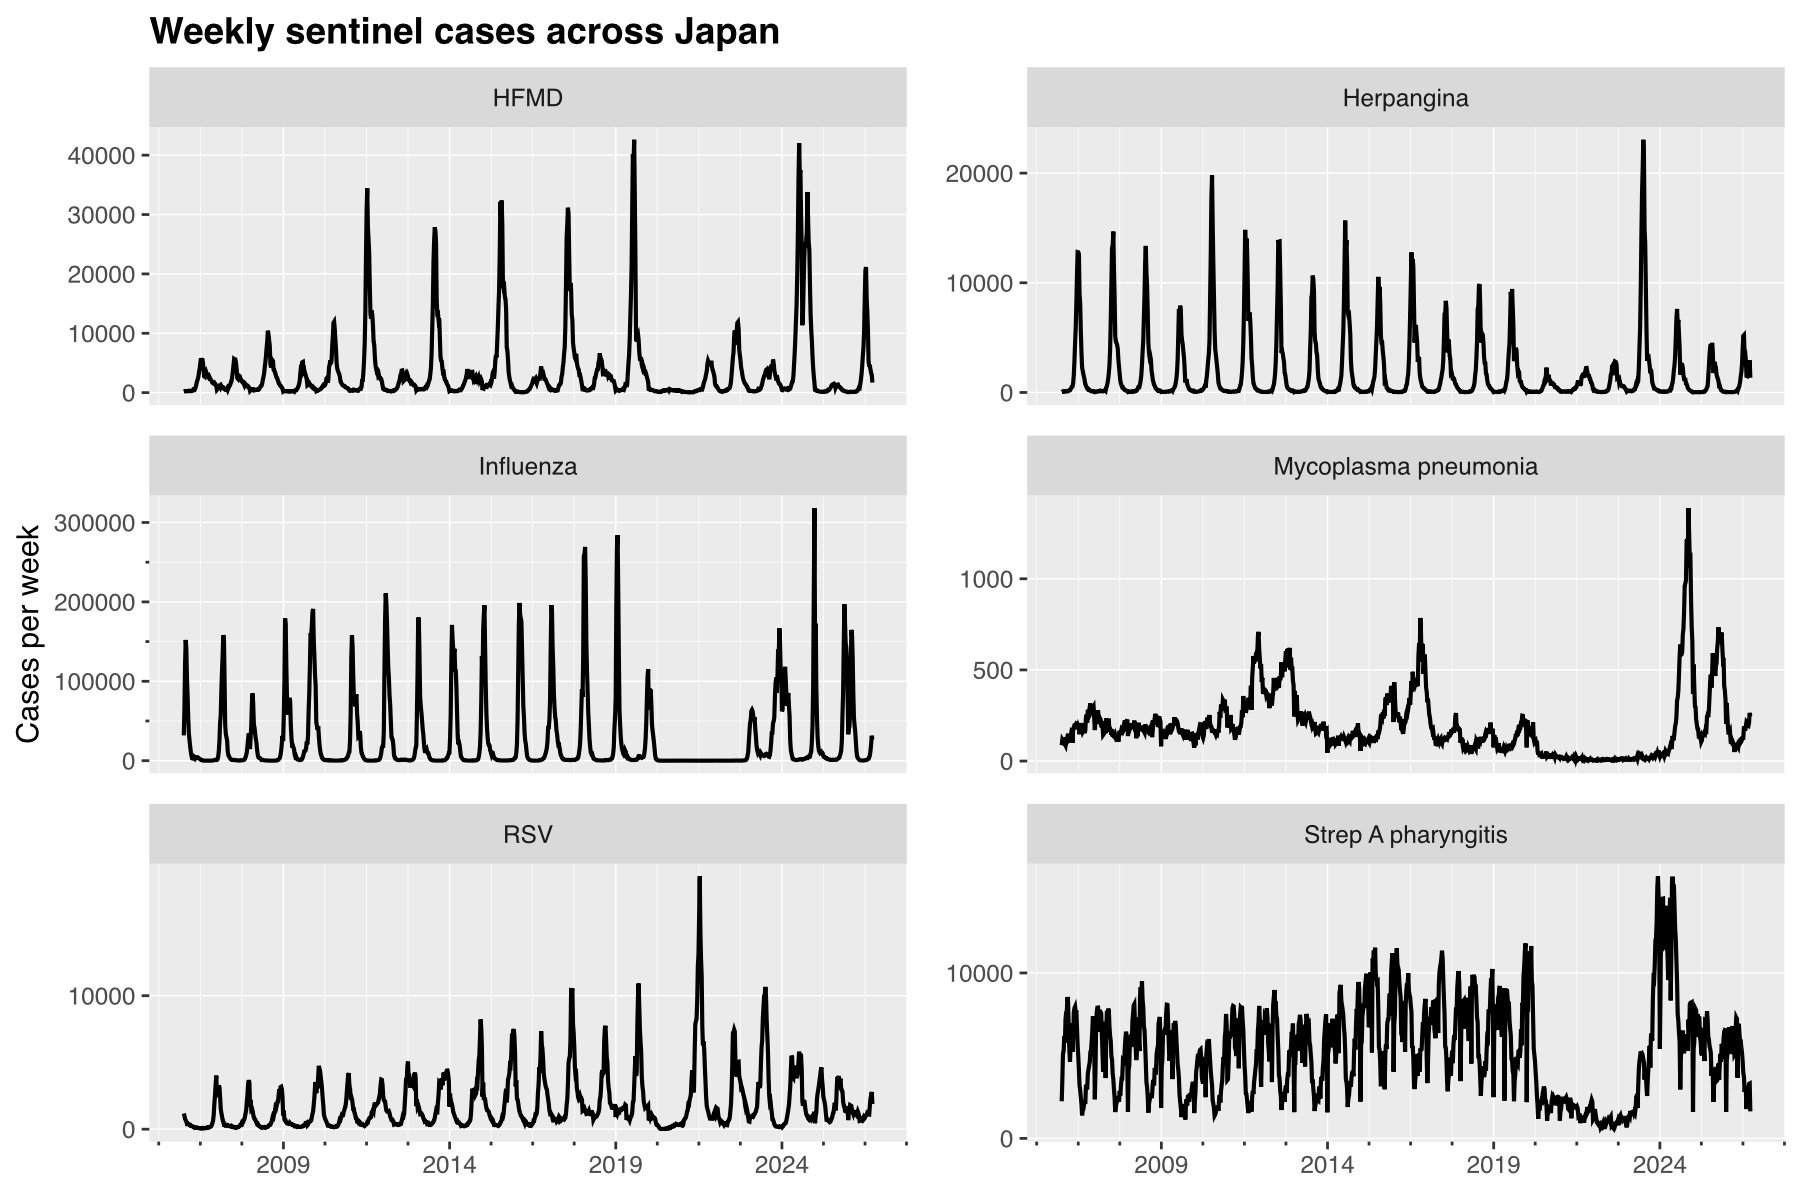

In [6]:
SELECT * FROM sentinel WHERE year >= 2006
VISUALISE date AS x, cases AS y
DRAW line
SCALE x SETTING breaks => '5 years' RENAMING * => '{:time %Y}'
FACET disease SETTING free => 'y', ncol => 2
LABEL
  title => 'Weekly sentinel cases across Japan',
  x => null,
  y => 'Cases per week'

Each panel has its own y-axis, as the diseases live on very different scales. A few things stand out:

+ Until 2020, most of these infections follow a very regular seasonal cycle.
+ In 2020 almost everything collapses, and influenza practically disappears for two full seasons.
+ The return is anything but regular: HFMD, *Mycoplasma pneumoniae* and Strep A pharyngitis all reach some of their highest weekly counts in the whole series after 2023.

## How big was the rebound?

To put a number on it, we can compare each year's total with the average of the 2010–2019 decade. Window functions work as usual in the SQL part, so we compute the ratios in a table first:

In [5]:
CREATE TABLE ratios AS
WITH yearly AS (
  SELECT disease, year, SUM(cases) AS cases
  FROM sentinel
  WHERE year BETWEEN 2010 AND 2025
  GROUP BY ALL
)
SELECT
  disease,
  year,
  cases / AVG(CASE WHEN year < 2020 THEN cases END) OVER (PARTITION BY disease) AS ratio,
  CASE WHEN ratio >= 1 THEN 'Above' ELSE 'Below' END AS vs_baseline
FROM yearly

And plot them as bars, with `PLACE` adding an annotation layer (here, a reference line at 1). The long `RENAMING` list only hides every year label except 2010, 2015, 2020 and 2025, as bars need an ordinal x-axis (more on that at the end) and I could not find a way to set its breaks directly:

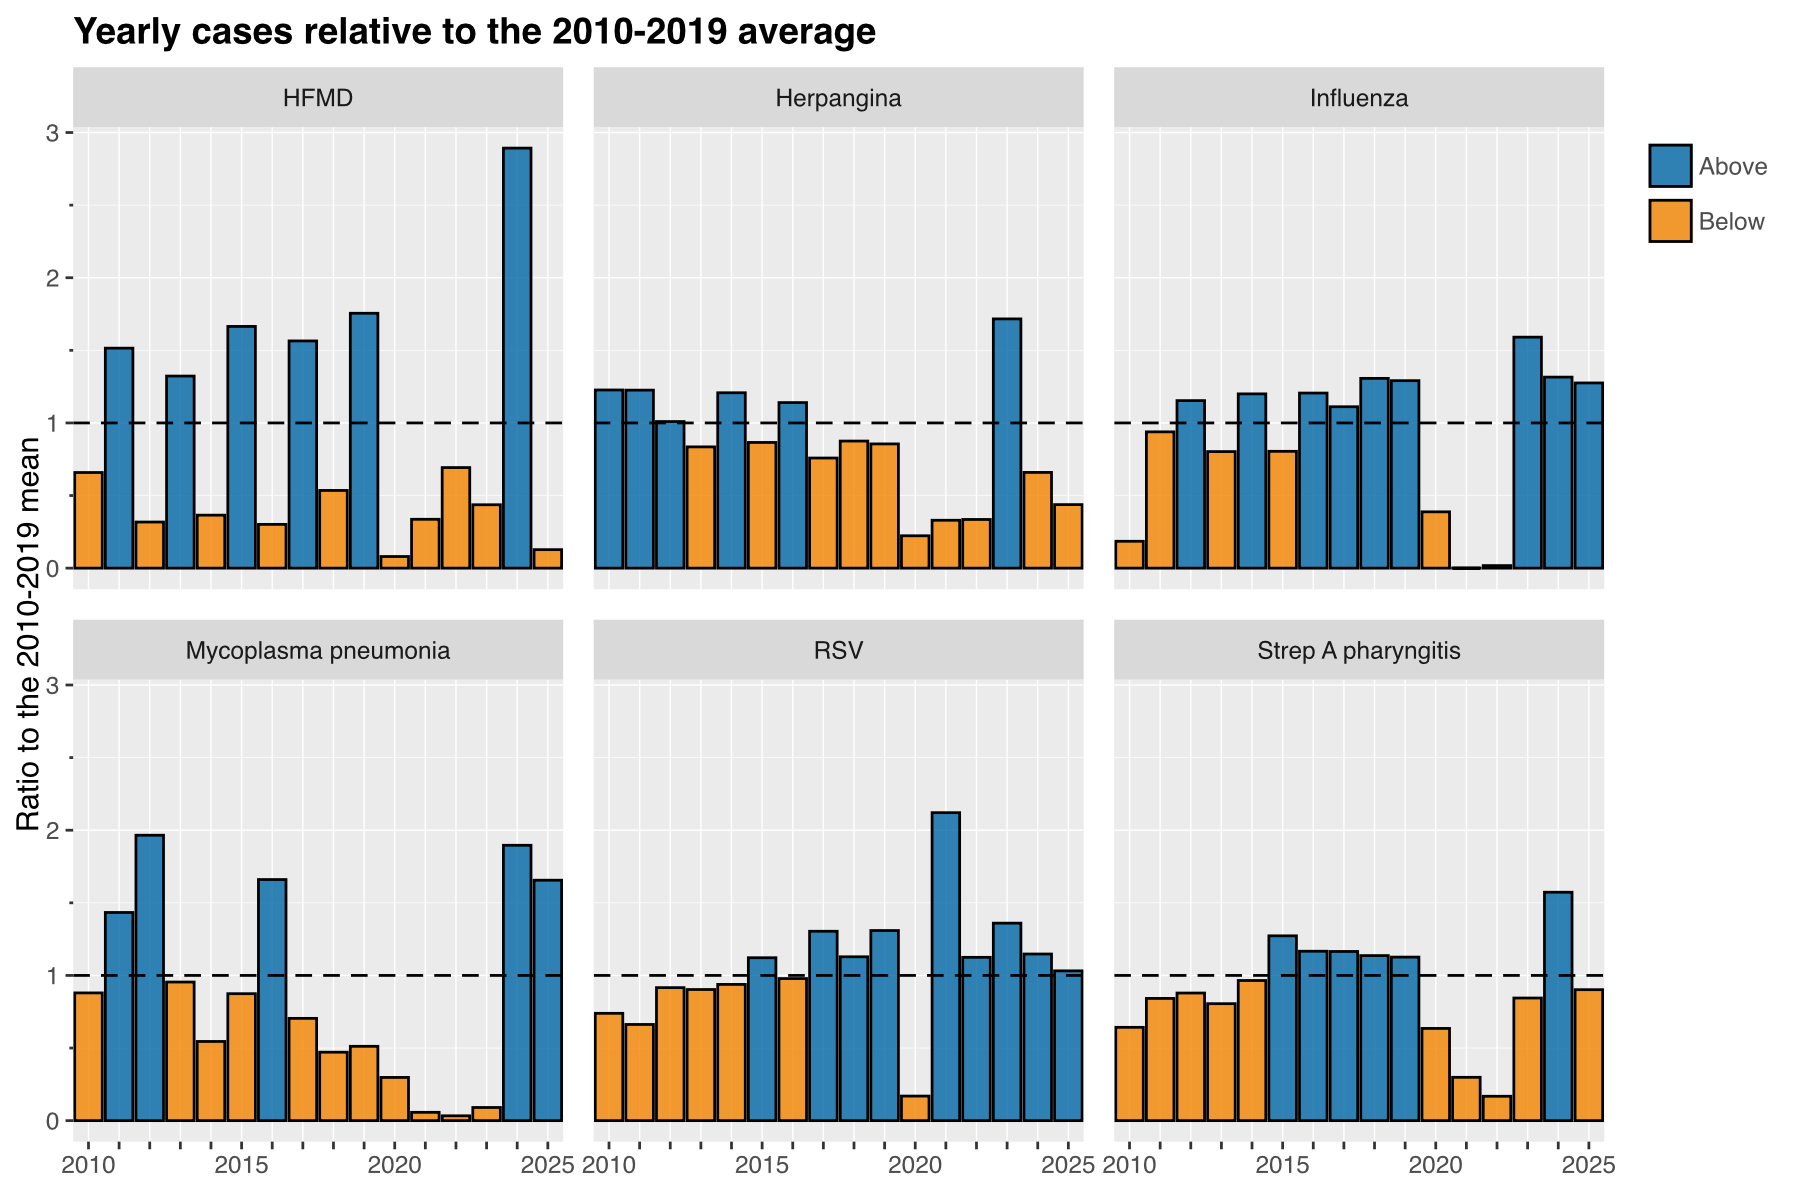

In [8]:
SELECT * FROM ratios
VISUALISE year AS x, ratio AS y, vs_baseline AS fill
DRAW bar
PLACE rule SETTING y => 1, linetype => 'dashed'
SCALE ORDINAL x RENAMING 2011 => null, 2012 => null, 2013 => null, 2014 => null, 2016 => null, 2017 => null, 2018 => null, 2019 => null, 2021 => null, 2022 => null, 2023 => null, 2024 => null
FACET disease SETTING ncol => 3
LABEL
  title => 'Yearly cases relative to the 2010-2019 average',
  x => null,
  y => 'Ratio to the 2010-2019 mean',
  fill => null

Influenza went down to practically zero in 2021 and 2022 (ratios of 0.00 and 0.02), and then came back above its pre-pandemic level, with 1.59 times the 2010–2019 average in 2023. RSV was the first to come back, with more than twice its usual yearly total in 2021 (2.12). HFMD had almost three times its usual total in 2024 (2.89), and *Mycoplasma pneumoniae* nearly doubled it (1.90), staying high in 2025 (1.66).

Initially I wrote the baseline with `AVG(cases) FILTER (WHERE year < 2020)`, which DuckDB is perfectly happy with. Unfortunately, at the time of writing, the `ggsql` parser fails with a "Parse tree contains errors" message when an aggregate `FILTER` clause appears in a query that also contains `VISUALISE` (presumably because `FILTER` is also a `ggsql` keyword). Rewriting it with a `CASE WHEN` inside the aggregate works around it, and computing the table in a separate, plain SQL cell avoids the problem altogether.

### Making it look like mine

So far I have used `ggsql`'s default look. How far can we get towards the style of my own figures? There is no theme system yet, so the background, grid, fonts and facet strips cannot be changed. What we *can* change is every colour that is mapped or set, either through the scales or by setting an aesthetic to a literal value in the layer. Here is the same plot with the red and blue I use in my papers for "before" and "after" comparisons, a lighter reference line, and a subtitle (labels are parsed as markdown, so italics work too):

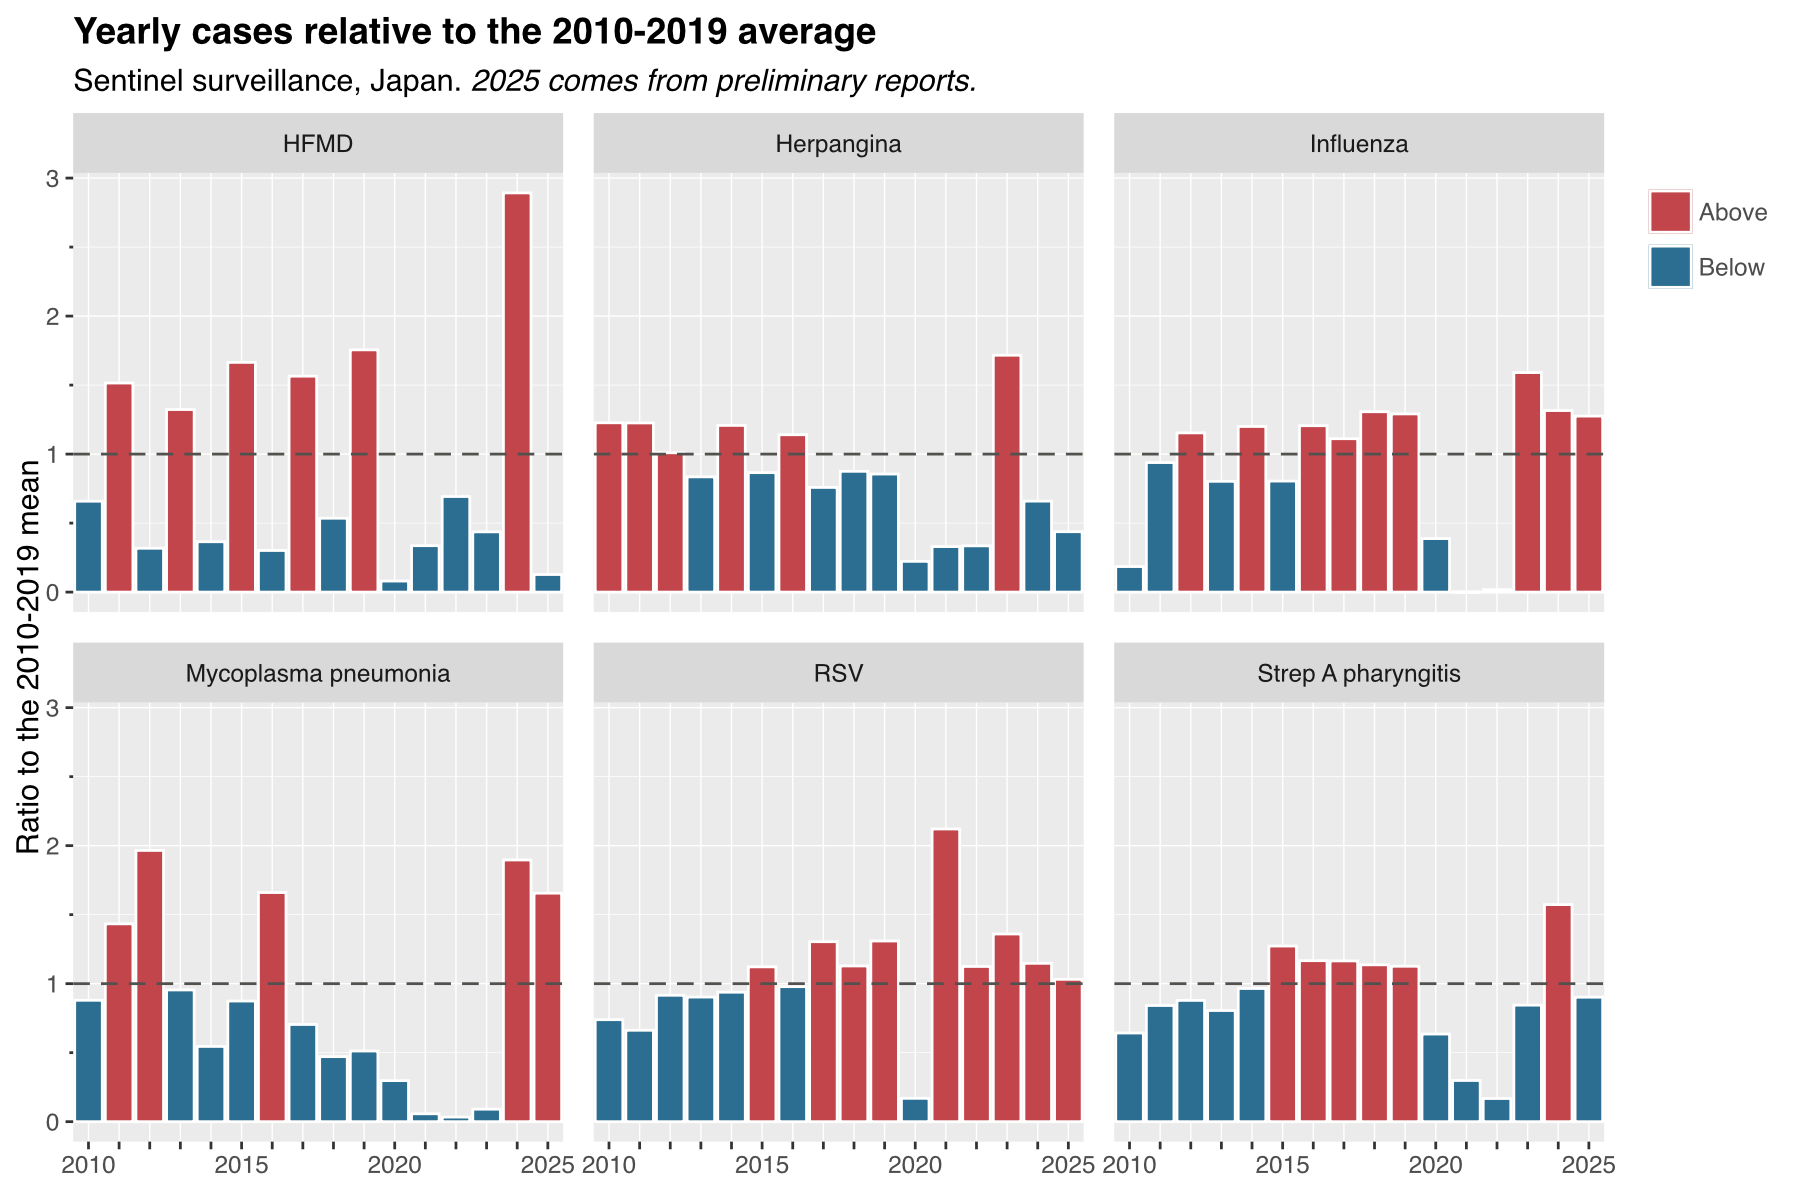

In [9]:
SELECT * FROM ratios
VISUALISE year AS x, ratio AS y, vs_baseline AS fill
DRAW bar SETTING opacity => 1, stroke => 'white'
PLACE rule SETTING y => 1, linetype => 'dashed', stroke => '#52514e'
SCALE ORDINAL x RENAMING 2011 => null, 2012 => null, 2013 => null, 2014 => null, 2016 => null, 2017 => null, 2018 => null, 2019 => null, 2021 => null, 2022 => null, 2023 => null, 2024 => null
SCALE fill FROM ['Above', 'Below'] TO ['#c2454b', '#2c6e91']
FACET disease SETTING ncol => 3
LABEL
  title => 'Yearly cases relative to the 2010-2019 average',
  subtitle => 'Sentinel surveillance, Japan. *2025 comes from preliminary reports.*',
  x => null,
  y => 'Ratio to the 2010-2019 mean',
  fill => null

Not bad, but not quite there either. For anything going into a paper I would still miss being able to set the font, drop the grey background and control the strips. For a blog post or a quick look at the data, though, it is more than enough, and the named palettes (`viridis`, `magma`, Crameri's scientific colour maps, and others) cover most needs without typing a single hex code, as the next sections show.

## RSV changed its season

The yearly totals hide something else that is visible in the first figure: RSV did not only come back stronger, it came back at a different time of the year. This is something I had already noticed when comparing RSV with Kawasaki disease, and a heatmap of the share of each year's cases falling in each ISO week makes it very clear. Some ISO years have 53 weeks, so I fold week 53 into week 52 to keep all the rows the same length, and `expand => 0` removes the default padding around the scales, so the tiles fill the whole panel:

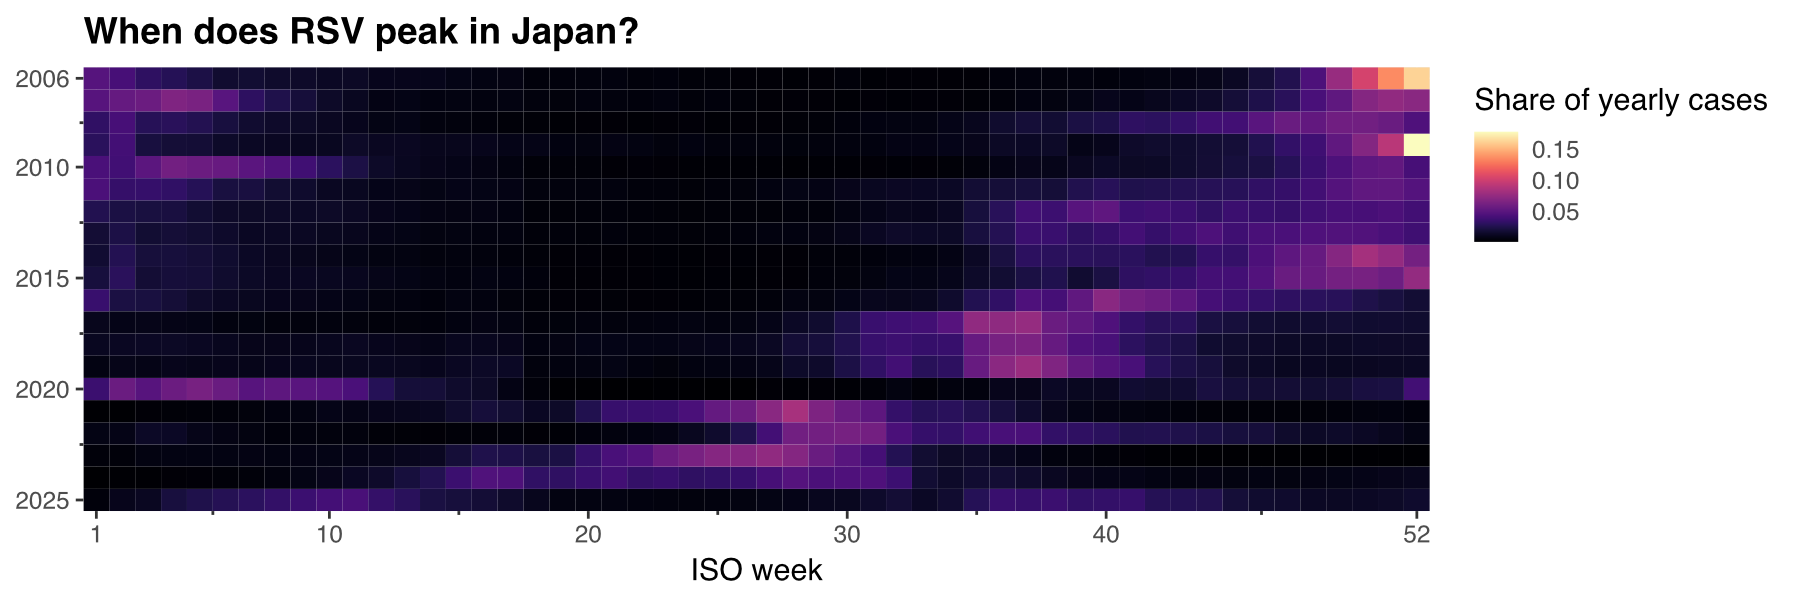

In [6]:
SELECT
  year,
  LEAST(week, 52) AS week,
  SUM(count) / SUM(SUM(count)) OVER (PARTITION BY year) AS share
FROM idwr
WHERE disease = 'Respiratory syncytial virus infection'
  AND year BETWEEN 2006 AND 2025
GROUP BY 1, 2
VISUALISE week AS x, year AS y, share AS fill
DRAW tile SETTING linewidth => 0, opacity => 1
SCALE fill TO magma
SCALE x SETTING expand => 0, breaks => [1, 10, 20, 30, 40, 52]
SCALE y SETTING reverse => true, expand => 0, breaks => [2006, 2010, 2015, 2020, 2025]
LABEL
  title => 'When does RSV peak in Japan?',
  x => 'ISO week',
  y => null,
  fill => 'Share of yearly cases'

Nationally, RSV peaked in weeks 50 to 52 in most years until 2015, that is, in winter. In 2016 the peak moved to week 40, and in 2017, 2018 and 2019 it came at week 37, at the beginning of autumn. Then 2020 brought the smallest peak in the series (1,126 cases in week 5, the tail of the 2019/20 season), and in 2021 RSV came back in summer, at week 28, with the highest weekly count in the series: 18,939 cases. From 2022 to 2024 it stayed in summer (weeks 27 to 30), and in the preliminary 2025 data it peaked at week 11.

## ...and almost everywhere at once

Since the data is reported by prefecture, we can check whether those changes happened across the whole country or only in some regions. For each prefecture and year we keep the week with the most cases, and colour it with one of `ggsql`'s cyclic palettes (`romao`), so that week 52 and week 1 get similar colours.

Discrete scales are sorted alphabetically by default (an `ORDER BY` in the query does not change that), so to get the prefectures in their usual north-to-south order we pass the full list of categories to the scale:

In [10]:
CREATE TABLE peaks AS
WITH ranked AS (
  SELECT
    prefecture,
    year,
    week,
    ROW_NUMBER() OVER (PARTITION BY prefecture, year ORDER BY count DESC) AS rn
  FROM idwr
  WHERE disease = 'Respiratory syncytial virus infection'
    AND year BETWEEN 2006 AND 2025
    AND count IS NOT NULL
)
SELECT prefecture, year, week AS peak_week
FROM ranked
WHERE rn = 1

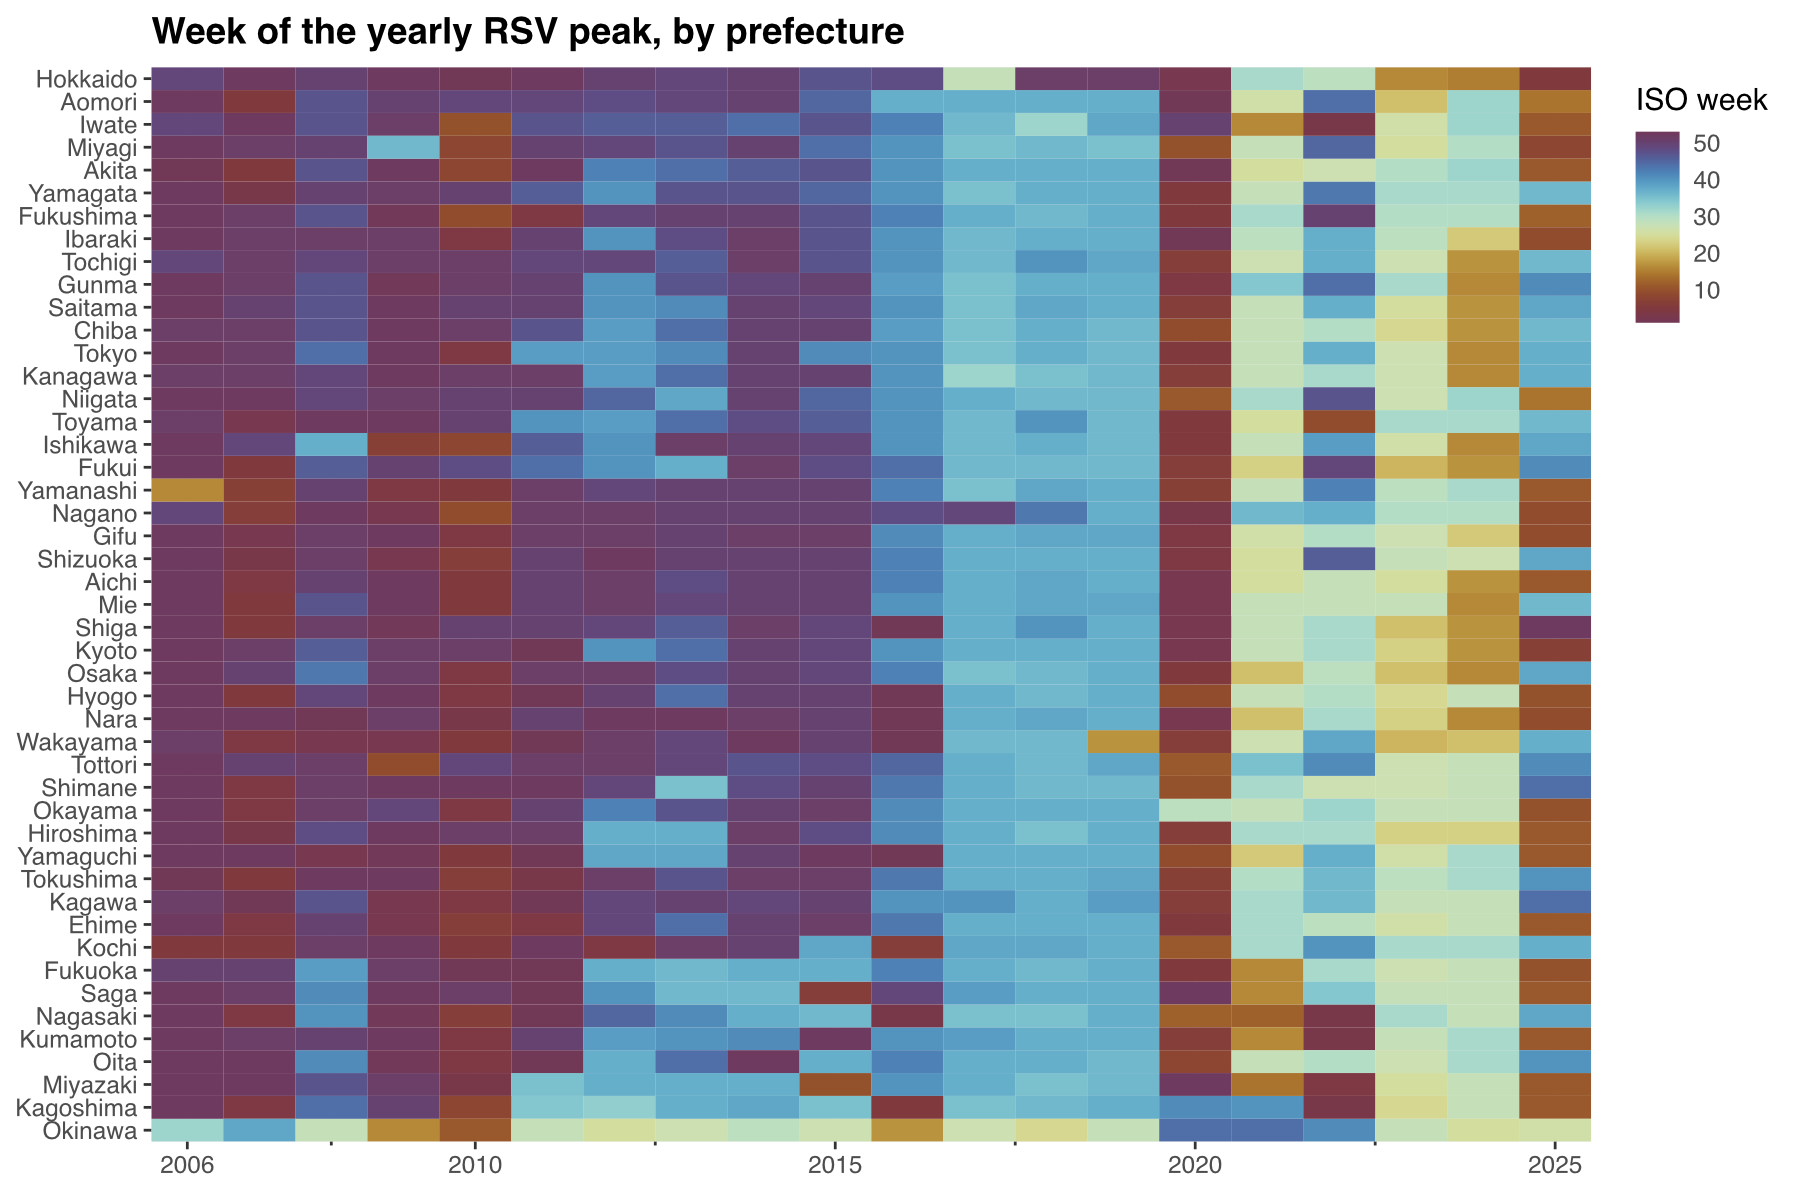

In [11]:
SELECT * FROM peaks
VISUALISE year AS x, prefecture AS y, peak_week AS fill
DRAW tile SETTING linewidth => 0, opacity => 1
SCALE x SETTING expand => 0, breaks => [2006, 2010, 2015, 2020, 2025]
SCALE DISCRETE y FROM ['Hokkaido', 'Aomori', 'Iwate', 'Miyagi', 'Akita', 'Yamagata', 'Fukushima', 'Ibaraki', 'Tochigi', 'Gunma', 'Saitama', 'Chiba', 'Tokyo', 'Kanagawa', 'Niigata', 'Toyama', 'Ishikawa', 'Fukui', 'Yamanashi', 'Nagano', 'Gifu', 'Shizuoka', 'Aichi', 'Mie', 'Shiga', 'Kyoto', 'Osaka', 'Hyogo', 'Nara', 'Wakayama', 'Tottori', 'Shimane', 'Okayama', 'Hiroshima', 'Yamaguchi', 'Tokushima', 'Kagawa', 'Ehime', 'Kochi', 'Fukuoka', 'Saga', 'Nagasaki', 'Kumamoto', 'Oita', 'Miyazaki', 'Kagoshima', 'Okinawa']
  SETTING reverse => true
SCALE fill FROM [1, 53] TO romao
LABEL
  title => 'Week of the yearly RSV peak, by prefecture',
  x => null,
  y => null,
  fill => 'ISO week'

The shift from winter to autumn around 2016–2017, the collapse of 2020 and the summer peak of 2021 all happened in practically every prefecture at the same time. After 2021 the picture gets noisier, with peaks anywhere between spring and autumn depending on the prefecture and the year. There are also two clear exceptions, at the two ends of the country:

+ **Hokkaido** kept its winter peak (weeks 47 to 52, or the first week of January) every year until 2019, except for 2017.
+ **Okinawa** was already peaking in summer before any of this happened, usually somewhere between weeks 24 and 32, and in 2020–2022 it peaked in autumn instead (weeks 41 to 44).

## Maps

A heatmap with prefectures as rows is compact, but for spatial patterns nothing beats a map. `ggsql` has a `spatial` layer for simple features, and DuckDB can read GeoJSON through its `spatial` extension, so maps are also possible without leaving SQL. First, we load the extension:

In [12]:
INSTALL spatial;
LOAD spatial;

For the prefecture boundaries I am using the GeoJSON from [dataofjapan/land](https://github.com/dataofjapan/land), whose `id` field follows the standard prefecture codes (1 for Hokkaido to 47 for Okinawa), the same order as the list above. As I usually do in my maps, I drop Okinawa, which is otherwise far enough to the south-west to ruin the aspect ratio of the whole figure, and clip away the remote islands of other prefectures (e.g. Ogasawara) with a bounding box:

In [13]:
CREATE TABLE prefectures AS
SELECT
  id AS pref_code,
  ST_Intersection(geom, ST_MakeEnvelope(128.5, 30.5, 146, 45.7)) AS geom
FROM ST_Read('https://raw.githubusercontent.com/dataofjapan/land/master/japan.geojson')
WHERE id <> 47

Then we join the peak weeks to the polygons for four years that summarise the story so far. Two details that cost me some time:

+ The spatial layer wants the geometries as Well-Known Binary. Passing DuckDB's native `GEOMETRY` column fails with an empty "Failed to execute SQL" error, while wrapping it in `ST_AsWKB()` works.
+ `FACET` on a numeric column bins it, so faceting by `year` directly gave me panels labelled "2014 – 2016" and similar. Casting the year to text fixes it.

In [14]:
CREATE TABLE peak_map AS
SELECT
  peaks.year::VARCHAR AS year,
  peaks.peak_week,
  ST_AsWKB(prefectures.geom) AS geom
FROM peaks
JOIN prefectures
  ON prefectures.pref_code = list_position(['Hokkaido', 'Aomori', 'Iwate', 'Miyagi', 'Akita', 'Yamagata', 'Fukushima', 'Ibaraki', 'Tochigi', 'Gunma', 'Saitama', 'Chiba', 'Tokyo', 'Kanagawa', 'Niigata', 'Toyama', 'Ishikawa', 'Fukui', 'Yamanashi', 'Nagano', 'Gifu', 'Shizuoka', 'Aichi', 'Mie', 'Shiga', 'Kyoto', 'Osaka', 'Hyogo', 'Nara', 'Wakayama', 'Tottori', 'Shimane', 'Okayama', 'Hiroshima', 'Yamaguchi', 'Tokushima', 'Kagawa', 'Ehime', 'Kochi', 'Fukuoka', 'Saga', 'Nagasaki', 'Kumamoto', 'Oita', 'Miyazaki', 'Kagoshima', 'Okinawa'], peaks.prefecture)
WHERE peaks.year IN (2014, 2018, 2021, 2024)

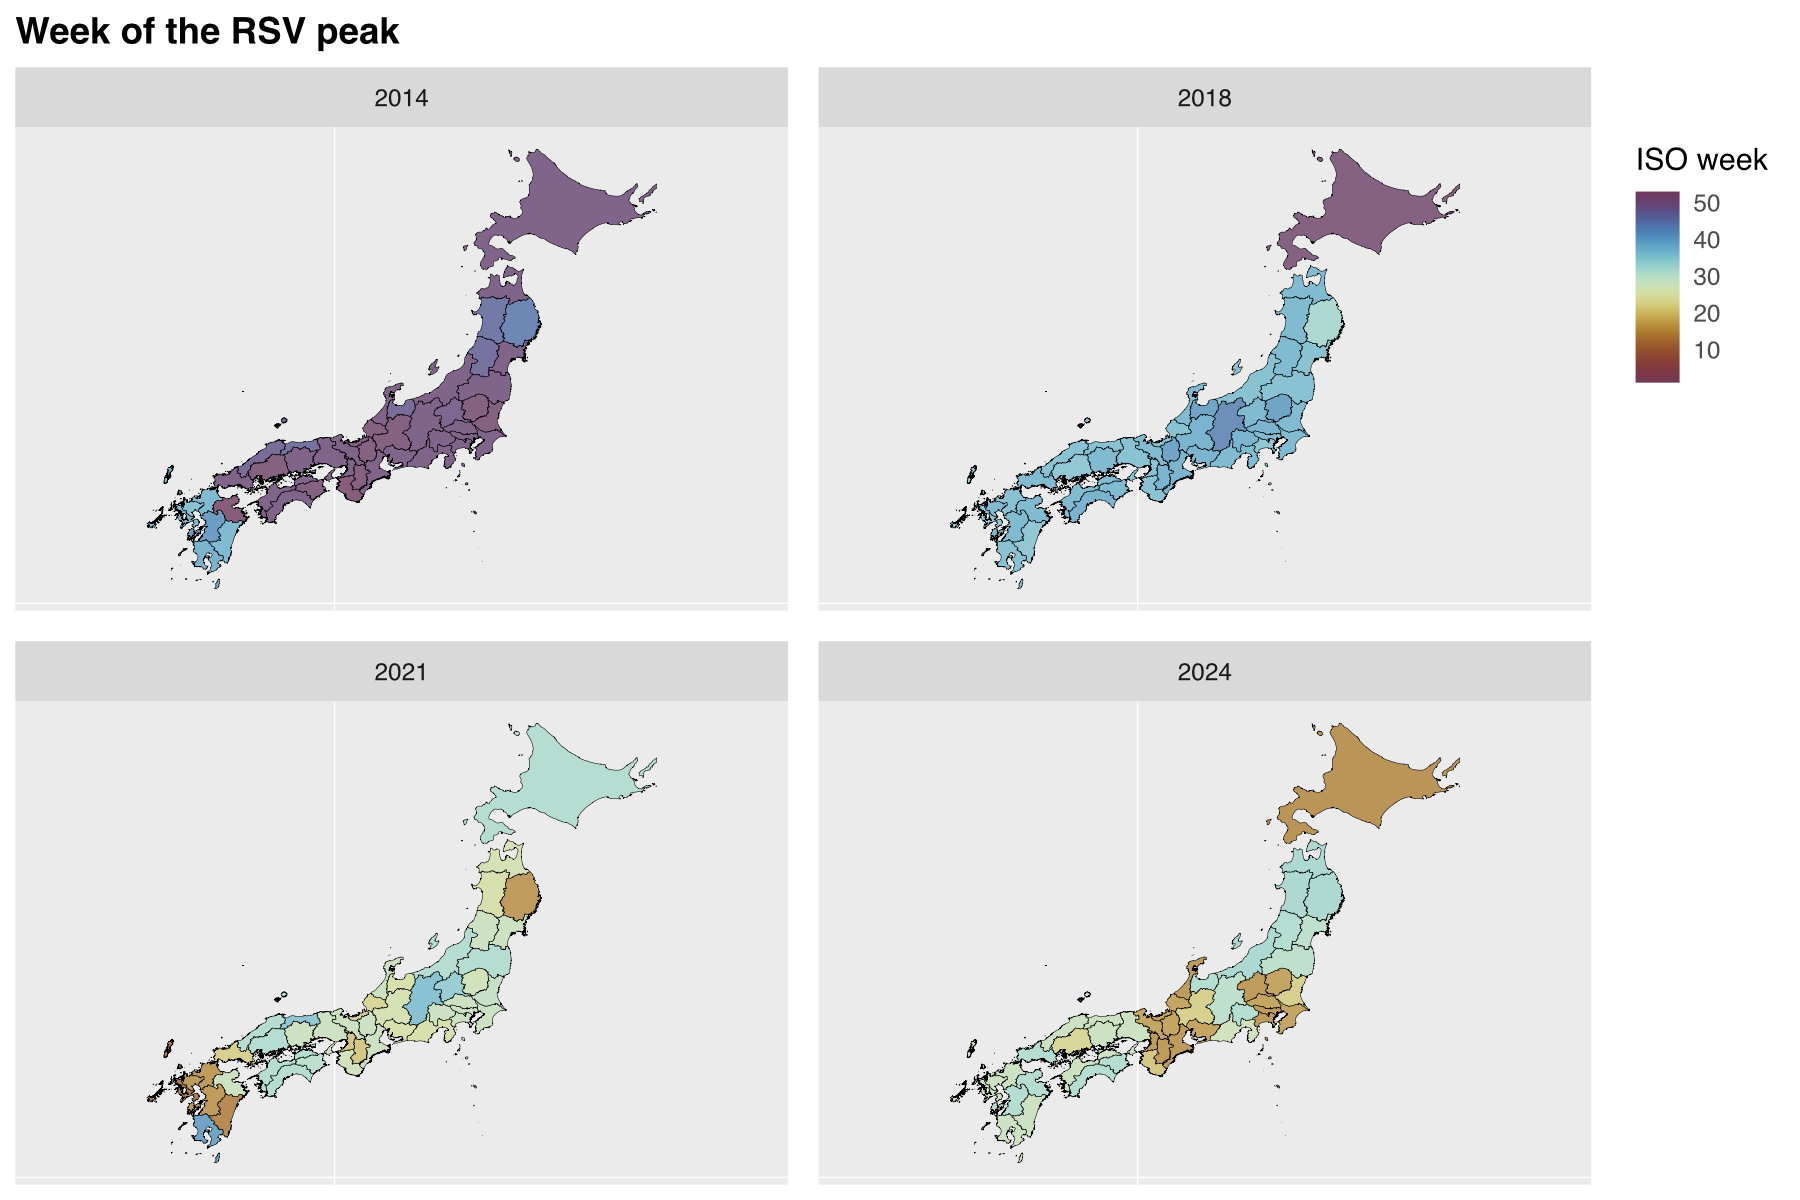

In [15]:
SELECT * FROM peak_map
VISUALISE peak_week AS fill
DRAW spatial SETTING linewidth => 0.2
SCALE fill FROM [1, 53] TO romao
FACET year SETTING ncol => 2
LABEL title => 'Week of the RSV peak', fill => 'ISO week'

In 2014, 39 of these 46 prefectures had their RSV peak in winter; the exceptions were six of the seven prefectures of Kyushu and Iwate, which peaked in autumn. In 2018, 44 of them peaked in autumn, with Hokkaido (week 51) as the clear outlier. In 2021, 34 prefectures peaked in summer, and by 2024 the peaks were split between summer (30) and spring (16).

## Why would you do this in SQL?

Going through this exercise I kept asking myself who would want to do all of this in pure SQL. If you already know Python or R, pandas/polars plus plotnine/ggplot2 give you more flexibility at every single step, and some of the workarounds above would not have been needed. For an analysis like the ones I usually do, which mix data wrangling, statistics and figures, I will keep using those.

That said, I can see a few situations where `ggsql` makes a lot of sense:

+ **The data lives in a database, and it is big.** `ggsql` translates its statistical layers into SQL that runs in the database, so (as their FAQ puts it) a histogram of a billion rows only ever fetches the counts of each bin. Besides DuckDB and SQLite, it can connect to Postgres, Snowflake, BigQuery, Databricks and others. Pulling a large table into a dataframe just to plot an aggregate of it is a very common waste.
+ **The people who need the plot speak SQL, not Python or R.** Plenty of analysts live in SQL editors and BI tools, and for them learning a grammar of graphics on top of a language they already know is a much smaller step than learning a new language.
+ **A plot as a single, declarative piece of text.** A `ggsql` query is the whole figure: data, transformations and plot specification in one string that can be stored, versioned or sent around. That also makes it a good target for LLMs (Posit even maintains a reference designed for them); asking an assistant for one declarative query seems much safer to me than asking it for Python code that you then have to execute.
+ **Plotting in the browser.** `ggsql` also compiles to WebAssembly, so it can run entirely client-side with no server and no data leaving the machine; the playground on their website works that way. A static site, like this blog, could plot a Parquet file like the ones in `jp-idwr-db` directly in the reader's browser.

So my conclusion is that I am not the target user, at least not for my day-to-day work, but that the target user definitely exists. And for a quick look at a Parquet file from the terminal or from Positron, I can see myself reaching for it.

## Rough edges

`ggsql` is still officially in alpha, so I was expecting rough edges, and I found a few. None of them was a blocker, but they are the kind of things I would expect anyone coming from `ggplot2` or `plotnine` to run into:

+ **Flaky high-resolution output.** At 200 dpi, the largest figure of the post (the six panels of the first plot) sometimes came back with no image and no error at all. Running the same cell again worked.
+ **One figure size per session.** There is no figure-size syntax, and the kernel takes the size from its environment when it starts, so all the figures in a session have the same dimensions. Giving a single figure a different shape means starting a new kernel and re-running whatever that figure depends on. In `plotnine` or Quarto with Python, that is one `figure_size` or `fig-height` away.
+ **Opaque errors.** Parsing problems give a generic "Parse tree contains errors" without pointing at the offending part of the query, and the spatial issue above gave an *empty* database error.
+ **SQL that DuckDB accepts but the `ggsql` parser does not.** Aggregate `FILTER` clauses and DuckDB list literals (`['a', 'b']`) both broke the parser when they appeared in a query with `VISUALISE`. Moving those steps to a plain SQL cell (one without `VISUALISE`) avoids the problem.
+ **Silent surprises with numeric columns.** A bar layer with a numeric `year` on the x-axis drew no bars at all (they need `SCALE ORDINAL x`), and faceting by a numeric column silently binned it into ranges.
+ **Category order.** Discrete axes are sorted alphabetically, and the only way I found to change that was to spell out the full list of categories in the scale.
+ **No theming.** As discussed above, colours are all you can customise for now.
+ **No plot composition.** There is nothing like `plotnine`'s composition operators (which I used in my [world population post](https://alfontal.dev/posts/world-population/world_pop_densities/)) or `patchwork`, so no marginal plots, insets or multi-panel figures beyond facets.
+ **One kernel per document.** A Quarto document runs on a single Jupyter kernel, so `ggsql` cells and Python cells cannot be mixed in the same notebook. For most of my analyses, which need things like wavelets or regression models alongside the plots, this alone rules it out.
+ **A moving target.** There have been six releases between May and September 2026 alone, and version 0.5.0 introduced a new renderer, so figures may change from one version to the next. If you want a document to keep rendering the same way, pin the version.

Most of these are what you would expect from an alpha release, and the pace of development suggests many of them will not last long.

As for `jp-idwr-db`, the whole point is that you should not need to think about where the data comes from, and the fact that this post did not need a single line of Python to use it is probably the best showcase I could make. If you work with Japanese surveillance data, give it a try: `pip install jp-idwr-db`, or simply grab the Parquet files from the [latest release](https://github.com/AlFontal/jp-idwr-db/releases/latest). The quirks of each dataset are documented in [DATASETS.md](https://github.com/AlFontal/jp-idwr-db/blob/main/docs/DATASETS.md), and the temporal coverage of every disease in [DISEASES.md](https://github.com/AlFontal/jp-idwr-db/blob/main/docs/DISEASES.md). Issues and suggestions are very welcome in the [repository](https://github.com/AlFontal/jp-idwr-db).

Stay posted for more, and feel free to comment below with any questions or comments!